# Sesión 3 - Parte 1: El Laboratorio Virtual de Calibración 3D

Para comprender cómo el algoritmo **DLT 3D** estima la matriz de proyección de la cámara, primero debemos simular el proceso físico e inverso: **la formación de la imagen**. En este experimento crearemos un escenario virtual interactivo con dos componentes fundamentales:

1. **Un Objeto de Calibración 3D:** Un cubo de alambre virtual de $100 \times 100 \times 100 \text{ mm}$ situado en el origen del espacio tridimensional.
2. **Una Cámara Pinhole Móvil:** Cuyos parámetros intrínsecos (distancia focal $f$) y extrínsecos (coordenadas de su centro óptico $C = [X_c, Y_c, Z_c]$ en el espacio) podréis modificar en tiempo real mediante deslizadores (*sliders*) .

### El Modelo de Cámara "Look-At"
Para facilitar el control de la cámara en el espacio 3D, implementamos una cámara que enfoca automáticamente al centro del cubo de calibración ($[50, 50, 50] \text{ mm}$). La matriz de rotación de la pose $R$ se calcula construyendo una base ortonormal a partir de tres vectores:
* El **eje óptico de la cámara ($\mathbf{z}_c$)**, que es el vector unitario que apunta desde el centro de la cámara $C$ hacia el objetivo.
* El **eje horizontal del sensor ($\mathbf{x}_c$)**, perpendicular al plano formado por el eje óptico y la vertical del mundo ($\mathbf{y}_{\text{world}}$).
* El **eje vertical del sensor ($\mathbf{y}_c$)**, que completa la base ortonormal dextrógira.

Una vez calculadas $R$ y $\mathbf{t} = -R \cdot C$, proyectamos cada punto del espacio $\mathbf{X}_w$ al píxel del sensor $\mathbf{x}_{\text{sensor}}$ mediante:
$$\mathbf{X}_c = R \mathbf{X}_w + \mathbf{t}$$
$$\mathbf{x}_{\text{sensor}} \sim K \mathbf{X}_c \implies \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} \sim \begin{bmatrix} f & 0 & u_0 \\ 0 & f & v_0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} X_c \\ Y_c \\ Z_c \end{bmatrix}$$


In [1]:
# Asegúrate de tener activo el backend interactivo en tu Jupyter Notebook
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from ipywidgets import interactive, HBox, VBox, Layout

# ==========================================================================
# 1. MODELADO DE LA CÁMARA CON SISTEMA DE ÓRBITA Y GIRO (ROLL)
# ==========================================================================
def look_at_with_roll(C, target, roll_deg=0.0, up=np.array([0.0, 1.0, 0.0])):
    """
    Construye las matrices extrínsecas R y t. 
    Aplica una rotación de Roll (giro sobre el eje óptico) tras apuntar al objetivo.
    """
    C = np.array(C, dtype=np.float64)
    target = np.array(target, dtype=np.float64)
    
    # Eje Z de la cámara (óptico): apunta del centro óptico al objetivo
    z_c = target - C
    z_c /= np.linalg.norm(z_c)
    
    # Eje X de la cámara (horizontal): perpendicular al plano Z y vertical del mundo
    x_c = np.cross(up, z_c)
    x_c /= np.linalg.norm(x_c)
    
    # Eje Y de la cámara (vertical): completa la base ortonormal
    y_c = np.cross(z_c, x_c)
    
    # Matriz de rotación de apuntamiento básica
    R_look = np.vstack([x_c, y_c, z_c])
    
    # Matriz de rotación de Roll (giro de la cámara sobre su propio lente)
    alpha = np.radians(roll_deg)
    R_roll = np.array([
        [np.cos(alpha),  np.sin(alpha), 0.0],
        [-np.sin(alpha), np.cos(alpha), 0.0],
        [0.0,            0.0,           1.0]
    ], dtype=np.float64)
    
    # La rotación final es el producto de ambas
    R = R_roll @ R_look
    t = -R @ C
    return R, t

def orbita_a_cartesiano(azimut_deg, elevacion_deg, distancia, target):
    """Convierte coordenadas de órbita esférica a posición cartesiana 3D"""
    theta = np.radians(azimut_deg)
    phi = np.radians(elevacion_deg)
    
    dx = distancia * np.cos(phi) * np.sin(theta)
    dy = distancia * np.sin(phi)
    dz = -distancia * np.cos(phi) * np.cos(theta)
    
    return target + np.array([dx, dy, dz])

# ==========================================================================
# 2. PROYECCIÓN PERSPECTIVA INTERACTIVA
# ==========================================================================
def simular_proyeccion(f, azimut, elevacion, roll, distancia):
    target = np.array([50.0, 50.0, 50.0], dtype=np.float64) # Centro del cubo
    
    # 1. Calcular la posición cartesiana de la cámara a partir de la órbita
    C = orbita_a_cartesiano(azimut, elevacion, distancia, target)
    
    # 2. Calcular pose de la cámara (R, t) aplicando el Giro (Roll)
    R, t = look_at_with_roll(C, target, roll_deg=roll)
    
    # 3. Definir parámetros intrínsecos K (Sensor VGA 640x480)
    u0, v0 = 320.0, 240.0
    K = np.array([
        [f, 0.0, u0],
        [0.0, f, v0],
        [0.0, 0.0, 1.0]
    ], dtype=np.float64)
    
    # Matriz de proyección completa M
    M = K @ np.hstack([R, t.reshape(3, 1)])
    
    # 4. Cubo de calibración 3D
    vertices = np.array([
        [0,0,0], [100,0,0], [100,100,0], [0,100,0], # Base
        [0,0,100], [100,0,100], [100,100,100], [0,100,100] # Tapa
    ], dtype=np.float64)
    
    aristas = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7)
    ]
    
    # Proyectar puntos 3D a píxeles 2D
    pts_sensor = []
    for pt in vertices:
        pt_hom = np.append(pt, 1.0)
        p_proy = M @ pt_hom
        p_2d = p_proy[:2] / p_proy[2] # <--- ¡CORREGIDO AQUÍ TAMBIÉN!
        pts_sensor.append(p_2d)
    pts_sensor = np.array(pts_sensor)
    
    # ==========================================================================
    # RENDERIZADO GRÁFICO
    # ==========================================================================
    fig = plt.figure(figsize=(10, 5))
    
    # Subplot 3D: Escena
    ax3d = fig.add_subplot(121, projection='3d')
    ax3d.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], color='#2980B9', s=45, label='Cubo (3D)')
    for arista in aristas:
        p1, p2 = vertices[arista[0]], vertices[arista[1]]
        ax3d.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#2980B9', alpha=0.6)
        
    ax3d.scatter(C[0], C[1], C[2], color='#E74C3C', s=100, marker='^', label='Cámara (C)')
    
    # Vector de dirección visual
    dir_vis = (target - C) / np.linalg.norm(target - C)
    eje_fin = C + 100.0 * dir_vis
    ax3d.plot([C[0], eje_fin[0]], [C[1], eje_fin[1]], [C[2], eje_fin[2]], color='#E74C3C', linestyle='--', linewidth=2, label='Eje Óptico')
    
    ax3d.set_xlim(-150, 250)
    ax3d.set_ylim(-150, 250)
    ax3d.set_zlim(-150, 250)
    ax3d.set_xlabel('X (mm)')
    ax3d.set_ylabel('Y (mm)')
    ax3d.set_zlabel('Z (mm)')
    ax3d.set_title('Escena Virtual 3D', fontsize=10, fontweight='bold')
    ax3d.legend(loc='upper right', fontsize=8)
    
    # Subplot 2D: Sensor
    ax2d = fig.add_subplot(122)
    ax2d.scatter(pts_sensor[:, 0], pts_sensor[:, 1], color='#E74C3C', s=55, edgecolors='black', zorder=3)
    for arista in aristas:
        p1, p2 = pts_sensor[arista[0]], pts_sensor[arista[1]]
        ax2d.plot([p1[0], p2[0]], [p1[1], p2[1]], color='#C0392B', linewidth=2)
        
    ax2d.set_xlim(0, 640)
    ax2d.set_ylim(480, 0) # Invertir eje Y para sistema de imagen estándar
    ax2d.set_xlabel('u (px)')
    ax2d.set_ylabel('v (px)')
    ax2d.set_title('Sensor de la Cámara (640x480 px)', fontsize=10, fontweight='bold')
    ax2d.grid(True, linestyle=':', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# ==========================================================================
# 3. CONTROLES INTERACTIVOS (SLIDERS)
# ==========================================================================
focal_slider = widgets.IntSlider(min=300, max=1200, step=50, value=600, description='Focal (f):', layout=Layout(width='280px'))
azimut_slider = widgets.IntSlider(min=0, max=360, step=5, value=45, description='Azimut (Horiz):', layout=Layout(width='280px'))
elev_slider = widgets.IntSlider(min=-85, max=85, step=5, value=30, description='Elev. (Vert):', layout=Layout(width='280px'))
roll_slider = widgets.IntSlider(min=-180, max=180, step=5, value=0, description='Giro (Roll):', layout=Layout(width='280px'))
dist_slider = widgets.IntSlider(min=150, max=500, step=10, value=300, description='Distancia:', layout=Layout(width='280px'))

dashboard = interactive(simular_proyeccion, f=focal_slider, azimut=azimut_slider, elevacion=elev_slider, roll=roll_slider, distancia=dist_slider)

controles_izq = VBox([focal_slider, azimut_slider, elev_slider])
controles_der = VBox([dist_slider, roll_slider])

display(HBox([controles_izq, controles_der], layout=Layout(justify_content='center', margin='10px')))
display(dashboard.out)

Output()

# Sesión 3 - Parte 2: Estimación de $M$ mediante DLT 3D y Normalización de Hartley

Con los puntos 3D de nuestro objeto de calibración ($\mathbf{X}_j$) y sus correspondientes píxeles 2D en el sensor ($\mathbf{x}_j$), podemos estimar los 11 grados de libertad de la matriz de proyección de la cámara $M$ de $3 \times 4$.

### 1. El Peligro Numérico (La necesidad de Hartley 3D)
Al igual que ocurría en el caso 2D en la Sesión 2, resolver el sistema directo $A\mathbf{m} = \mathbf{0}$ utilizando píxeles crudos (del orden de $10^2$ o $10^3$) y coordenadas del mundo real (en milímetros) produce una matriz de diseño $A$ con un número de condición desastroso. Cualquier mínimo ruido de digitalización destrozaría la calibración.

Para evitarlo, aplicamos la **Normalización Isótropa de Hartley extendida a 3D**:
* **En el plano del sensor (2D):** Desplazamos los puntos para que su centroide esté en el origen $(0,0)$ y los escalamos para que la distancia media al origen sea $\sqrt{2}$. Esto nos da la matriz de transformación $T_{2D}$.
* **En el espacio real (3D):** Desplazamos los puntos para que su centroide esté en el origen $(0,0,0)$ y los escalamos para que su distancia media al origen sea **$\sqrt{3}$** (la extensión natural de la esfera unitaria en tres dimensiones). Esto nos da la matriz de transformación $T_{3D}$.

### 2. Planteamiento del Sistema Lineal Homogéneo
Para cada correspondencia de puntos normalizados $\tilde{\mathbf{X}}_j = [X_j, Y_j, Z_j, 1]^T$ y $\tilde{\mathbf{x}}_j = [u_j, v_j, 1]^T$, la relación de proyección homogénea $\tilde{\mathbf{x}}_j \times M' \tilde{\mathbf{X}}_j = \mathbf{0}$ nos aporta dos ecuaciones linealmente independientes:

$$\begin{bmatrix}
\mathbf{0}^T & -\tilde{\mathbf{X}}_j^T & v_j \tilde{\mathbf{X}}_j^T \\
\tilde{\mathbf{X}}_j^T & \mathbf{0}^T & -u_j \tilde{\mathbf{X}}_j^T
\end{bmatrix} \begin{bmatrix} \mathbf{m}_1 \\ \mathbf{m}_2 \\ \mathbf{m}_3 \end{bmatrix} = \mathbf{0}$$

Donde $\mathbf{m}_i^T$ es la fila $i$ de la matriz de cámara normalizada $M'$. Apilando las ecuaciones para nuestros $N \ge 6$ puntos, construimos una matriz $A$ de $2N \times 12$ y resolvemos mediante la **SVD** de $A$. El vector $\mathbf{m}$ óptimo será la última columna de la matriz $V$ (asociada al autovalor más pequeño).

### 3. Denormalización
Una vez obtenida la matriz normalizada $M'$, recuperamos la matriz física real $M$ deshaciendo los cambios de escala y traslación:
$$M = T_{2D}^{-1} M' T_{3D}$$

In [2]:
import numpy as np

# ==========================================================================
# 1. DESCOMPOSICIÓN RQ CORREGIDA Y CON RESTRICCIONES FÍSICAS (Reutilizada)
# ==========================================================================

# ==========================================================================
# 2. ALGORITMO DLT 3D CON NORMALIZACIÓN ISÓTROPA DE HARTLEY
# ==========================================================================
def normalizar_puntos_2d(pts):
    """Normaliza puntos 2D para que el centroide sea (0,0) y la dist media sea sqrt(2)"""
    pts = np.array(pts, dtype=np.float64)
    centroid = np.mean(pts[:, :2], axis=0)
    pts_centrados = pts[:, :2] - centroid
    
    dist_media = np.mean(np.linalg.norm(pts_centrados, axis=1))
    escala = np.sqrt(2.0) / dist_media
    
    # AHURA SÍ: Indexamos centroid[0] para X y centroid[1] para Y
    T = np.array([
        [escala, 0.0,    -escala * centroid[0]],
        [0.0,    escala, -escala * centroid[1]],
        [0.0,    0.0,    1.0]
    ], dtype=np.float64)
    
    return T

def normalizar_puntos_3d(pts):
    """Normaliza puntos 3D para que el centroide sea (0,0,0) y la dist media sea sqrt(3)"""
    pts = np.array(pts, dtype=np.float64)
    centroid = np.mean(pts[:, :3], axis=0)
    pts_centrados = pts[:, :3] - centroid
    
    dist_media = np.mean(np.linalg.norm(pts_centrados, axis=1))
    escala = np.sqrt(3.0) / dist_media
    
    # AHORA SÍ: Indexamos centroid[0], centroid[1] y centroid[2]
    T = np.array([
        [escala, 0.0,    0.0,    -escala * centroid[0]],
        [0.0,    escala, 0.0,    -escala * centroid[1]],
        [0.0,    0.0,    escala, -escala * centroid[2]],
        [0.0,    0.0,    0.0,    1.0]
    ], dtype=np.float64)
    
    return T

def calibrar_camara_dlt(pts_3d, pts_2d):
    N = len(pts_3d)
    T2D = normalizar_puntos_2d(pts_2d)
    T3D = normalizar_puntos_3d(pts_3d)
    
    pts_2d_hom = np.hstack([pts_2d[:, :2], np.ones((N, 1))])
    pts_3d_hom = np.hstack([pts_3d[:, :3], np.ones((N, 1))])
    
    pts_2d_norm = (T2D @ pts_2d_hom.T).T
    pts_3d_norm = (T3D @ pts_3d_hom.T).T
    
    A = []
    for i in range(N):
        X = pts_3d_norm[i]
        u, v = pts_2d_norm[i, 0], pts_2d_norm[i, 1]
        A.append(np.hstack([np.zeros(4), -X,  v * X]))
        A.append(np.hstack([X,  np.zeros(4), -u * X]))
        
    A = np.array(A, dtype=np.float64)
    _, _, Vt = np.linalg.svd(A)
    M_norm = Vt[-1, :].reshape((3, 4))
    
    M = np.linalg.inv(T2D) @ M_norm @ T3D
    
    # CORRECTO: Forzamos que el elemento M_34 de la esquina inferior derecha sea positivo
    escala = np.linalg.norm(M[2, :3])
    M = M / escala
    
    # 2. Orientación física: forzamos que la profundidad (t_z) sea positiva
    # o que el eje óptico apunte en la dirección correcta.
    if M[2, 3] < 0:
        M = -M
        
    return M
        
    return M

# ==========================================================================
# 3. ESCENARIO DE SIMULACIÓN Y EVALUACIÓN DE PRECISIÓN
# ==========================================================================
# Parámetros reales de diseño (La verdad de la cámara virtual)
f_real = 750.0
C_real = np.array([250.0, 180.0, -320.0]) # Posición en mm
target = np.array([50.0, 50.0, 50.0])

# Obtenemos la pose real simulada
from scipy.spatial.transform import Rotation as Rot
R_real = Rot.from_euler('xyz', [15.0, 30.0, 10.0], degrees=True).as_matrix()
t_real = -R_real @ C_real

K_real = np.array([
    [f_real, 0.0,    320.0],
    [0.0,    f_real, 240.0],
    [0.0,    0.0,    1.0]
], dtype=np.float64)

M_real = K_real @ np.hstack([R_real, t_real.reshape(3, 1)])

# Patrón de calibración: 8 esquinas del cubo de 100mm
vertices_3d = np.array([
    [0.0, 0.0, 0.0], [100.0, 0.0, 0.0], [100.0, 100.0, 0.0], [0.0, 100.0, 0.0],
    [0.0, 0.0, 100.0], [100.0, 0.0, 100.0], [100.0, 100.0, 100.0], [0.0, 100.0, 100.0]
], dtype=np.float64)

# Proyectamos al sensor
vertices_2d = []
for pt in vertices_3d:
    p_proy = M_real @ np.append(pt, 1.0)
    vertices_2d.append(p_proy[:2] / p_proy[2]) # <--- ¡CORREGIDO AQUÍ (añadido el [2])!
vertices_2d = np.array(vertices_2d)

# Simular ruido de digitalización realista de +/- 0.8 píxeles en las esquinas
np.random.seed(101)
ruido = np.random.normal(0, 0.1, vertices_2d.shape)
vertices_2d_ruidosos = vertices_2d + ruido

# ==========================================================================
# 4. CALIBRACIÓN Y EXTRACCIÓN MEDIANTE DESCOMPOSICIÓN RQ FÍSICA
# ==========================================================================
M_est = calibrar_camara_dlt(vertices_3d, vertices_2d_ruidosos)

# ==========================================================================
# 5. REPORTE COMPARATIVO DE MATRICES (DÓNDE OCURRE LA MAGIA DOCENTE)
# ==========================================================================
np.set_printoptions(suppress=True, precision=2)

print("=" * 85)
print("             REPORTE DOCENTE DE METROLOGÍA 3D Y CALIBRACIÓN ")
print("=" * 85)
print("Se ha calibrado el sistema con un ruido de sensor simulado de ± 0.1 píxeles.")
print("-" * 85)

print(M_real)
print("\nEstimada por Hartley + DLT:")
print(M_est)



             REPORTE DOCENTE DE METROLOGÍA 3D Y CALIBRACIÓN 
Se ha calibrado el sistema con un ruido de sensor simulado de ± 0.1 píxeles.
-------------------------------------------------------------------------------------
[[    479.65      41.51     658.11   83211.16]
 [     -7.21     784.09      72.5  -116133.24]
 [     -0.5        0.22       0.84     352.34]]

Estimada por Hartley + DLT:
[[    481.11      40.22     658.35   83508.08]
 [     -7.69     786.43      73.01 -116428.63]
 [     -0.5        0.22       0.84     353.38]]


# Sesión 3.- Parte 3: Calcular la factorización

La matriz de proyección se descompone como:
$$M = [A \mid \mathbf{b}] = K [R \mid \mathbf{t}]$$

Donde:
* $K$ es la matriz de **parámetros intrínsecos** ($3 \times 3$, triangular superior).
* $R$ es la matriz de **rotación de la pose** ($3 \times 3$, ortogonal).
* $\mathbf{t}$ es el vector de **traslación** ($3 \times 1$).

Para aislar $K$ y $R$ a partir de la submatriz izquierda $A = K \cdot R$, necesitamos una descomposición de tipo **Triangular Superior $\times$ Ortogonal**.

### El conflicto del álgebra estándar: QR vs RQ
1. **Factorización $QR$ (Estándar de primero de carrera):** Descompone una matriz $A$ en el orden $Q \cdot R$, donde $Q$ es ortogonal y $R$ es triangular superior. NumPy la incluye de forma nativa en `numpy.linalg.qr`. **No nos sirve directamente** porque el orden obtenido es inverso al físico ($R \cdot Q \neq Q \cdot R$).
2. **Factorización $RQ$:** Descompone la matriz en el orden $R \cdot Q$, donde la matriz triangular superior queda a la izquierda (nuestra $K$) y la ortogonal a la derecha (nuestra $R$).

### El "Truco" de la Matriz de Permutación $J$
Para calcular la descomposición $RQ$ utilizando el resolvedor estándar $QR$ de NumPy, aplicamos una transformación simétrica usando la matriz de permutación inversa $J$ (que revierte el orden de filas y columnas):

$$J = \begin{bmatrix} 0 & 0 & 1 \\ 0 & 1 & 0 \\ 1 & 0 & 0 \end{bmatrix}$$

Como $J^2 = I$ y $J^T = J$, podemos operar sobre la traspuesta de la submatriz rotada $J A^T J$, resolver su $QR$ estándar y deshacer el cambio:

$$J A^T J = Q_{qr} R_{qr} \implies A = (J R_{qr}^T J) (J Q_{qr}^T J) = K \cdot R$$

Donde $K = J R_{qr}^T J$ resulta en una matriz triangular superior y $R = J Q_{qr}^T J$ es una matriz ortogonal.


In [3]:
def calcular_centro_optico(M):
    """
    Calcula la posición 3D (X, Y, Z) del centro óptico de la cámara C
    resolviendo para el espacio nulo de M (M * C_hom = 0).
    """
    _, _, Vt = np.linalg.svd(M)
    C_hom = Vt[-1, :] # Espacio nulo de la matriz 3x4 M
    
    # CORRECTO: Dividimos por el factor homogéneo C_hom[3] (la W)
    return C_hom[:3] / C_hom[3] 
    
def rq_decomposición_cruda(A):
    """Calcula la descomposición RQ básica usando el truco de la matriz J"""
    J = np.array([
        [0.0, 0.0, 1.0],
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0]
    ], dtype=np.float64)
    
    A_rotada = J @ A.T @ J
    Q_qr, R_qr = np.linalg.qr(A_rotada)
    
    K_cruda = J @ R_qr.T @ J
    R_cruda = J @ Q_qr.T @ J
    return K_cruda, R_cruda

def rq_decomposition_fisica(A):
    """Factoriza A = K * R con restricciones físicas (diag(K) > 0, K_33 = 1.0, det(R) = +1)"""
    # Paso 0: Signo global homogéneo para posibilitar det(R) = +1
    if np.linalg.det(A) < 0:
        A = -A
        
    K, R = rq_decomposición_cruda(A)
    
    # 1. Asegurar focales positivas en la diagonal
    for i in range(3):
        if K[i, i] < 0:
            K[:, i] = -K[:, i]
            R[i, :] = -R[i, :]
            
    # 2. Normalizar escala para que K_33 = 1.0 (¡Corregido!)
    escala = K[2][2]
    K /= escala
    
    return K, R


In [4]:
K_est, R_est = rq_decomposition_fisica(M_est[:, :3])
C_est = calcular_centro_optico(M_est)


print("\n📊 [1] COMPARACIÓN DE PARÁMETROS INTRÍNSECOS (Matriz K)")
print("Real de diseño:")
print(K_real)
print("\nEstimada por RQ:")
print(K_est)
print(f"--> Error en Focal (fx): {np.abs(K_real[0,0] - K_est[0,0]):.2f} px")
print(f"--> Error en Punto Principal (u0, v0): ({np.abs(K_real[0,2] - K_est[0,2]):.2f}, {np.abs(K_real[1,2] - K_est[1,2]):.2f}) px")
print("-" * 85)

print("\n🔄 [2] COMPARACIÓN DE LA ROTACIÓN DE LA POSE (Matriz R)")
print("Real de diseño:")
print(R_real)
print("\nEstimada por RQ:")
print(R_est)
# Error angular global aproximado en grados
error_rot_rad = np.arccos(np.clip((np.trace(R_real.T @ R_est) - 1.0) / 2.0, -1.0, 1.0))
print(f"--> Error de orientación de la pose: {np.degrees(error_rot_rad):.3f} grados")
print("-" * 85)

print("\n📍 [3] COMPARACIÓN DE LA POSICIÓN FÍSICA DE LA CÁMARA (Centro C)")
print(f"C Real de diseño (mm):  {C_real}")
print(f"C Estimado por DLT (mm): {np.round(C_est, 2)}")
print(f"--> Desviación espacial final de la cámara: {np.linalg.norm(C_real - C_est):.2f} mm")
print("=" * 85)


📊 [1] COMPARACIÓN DE PARÁMETROS INTRÍNSECOS (Matriz K)
Real de diseño:
[[750.   0. 320.]
 [  0. 750. 240.]
 [  0.   0.   1.]]

Estimada por RQ:
[[751.7   -0.27 318.54]
 [  0.   752.75 239.23]
 [  0.    -0.     1.  ]]
--> Error en Focal (fx): 1.70 px
--> Error en Punto Principal (u0, v0): (1.46, 0.77) px
-------------------------------------------------------------------------------------

🔄 [2] COMPARACIÓN DE LA ROTACIÓN DE LA POSE (Matriz R)
Real de diseño:
[[ 0.85 -0.04  0.52]
 [ 0.15  0.97 -0.17]
 [-0.5   0.22  0.84]]

Estimada por RQ:
[[ 0.85 -0.04  0.52]
 [ 0.15  0.97 -0.17]
 [-0.5   0.22  0.84]]
--> Error de orientación de la pose: 0.157 grados
-------------------------------------------------------------------------------------

📍 [3] COMPARACIÓN DE LA POSICIÓN FÍSICA DE LA CÁMARA (Centro C)
C Real de diseño (mm):  [ 250.  180. -320.]
C Estimado por DLT (mm): [ 249.91  180.24 -320.49]
--> Desviación espacial final de la cámara: 0.55 mm


# Sesión 3 - Parte 3: ¿Cómo lo resolveríamos en la práctica profesional con OpenCV?

Hemos construido desde cero un calibrador de cámara 3D completo utilizando el algoritmo **DLT 3D** con normalización de Hartley y una factorización **RQ física**. 
En entornos profesionales o en código de producción, no es necesario programar la factorización RQ y la corrección de signos a mano. **OpenCV** cuenta con funciones altamente optimizadas que resuelven esto en una sola línea de código.

### La Función `cv2.decomposeProjectionMatrix`
La librería OpenCV incluye la función `cv2.decomposeProjectionMatrix()`, que toma una matriz de proyección $M$ de $3 \times 4$ y realiza exactamente la misma factorización $RQ$ y correcciones de signos físicos que hemos estudiado:
$$\text{K, R, t\_hom, ...} = \text{cv2.decomposeProjectionMatrix}(M)$$

Donde:
* **`K`**: Es la matriz de parámetros intrínsecos de $3 \times 3$. OpenCV la normaliza automáticamente para que $K_{3,3} = 1.0$.
* **`R`**: Es la matriz de rotación de la pose ($3 \times 3$) físicamente consistente ($\det(R) = +1$).
* **`t_hom`**: Es el **centro de la cámara** en coordenadas homogéneas ($4 \times 1$). Para recuperar la posición cartesiana real de la cámara en milímetros ($C = [X, Y, Z]^T$), dividimos las primeras tres componentes por la cuarta:
  $$C = \frac{\mathbf{t}_{\text{hom}, 0:3}}{\mathbf{t}_{\text{hom}, 3}}$$

In [5]:
import cv2

# ==========================================================================
# 1. EJECUCIÓN DE LA DESCOMPOSICIÓN DE OPENCV
# ==========================================================================
# Extraemos los parámetros de la matriz M_est estimada con tu DLT 3D
K_cv, R_cv, t_hom_cv, _, _, _, _ = cv2.decomposeProjectionMatrix(M_est)

# A. Asegurar normalización de escala homogénea (K_33 = 1)
K_cv_norm = K_cv / K_cv[2, 2]

# B. Recuperar el centro de la cámara en coordenadas cartesianas reales (mm)
# Dividimos las componentes espaciales por la cuarta componente homogénea (la W)
C_cv = (t_hom_cv[:3] / t_hom_cv[3]).flatten()

# ==========================================================================
# 2. REPORTE COMPARATIVO FINAL: NUESTRO CÓDIGO VS OPENCV
# ==========================================================================
np.set_printoptions(suppress=True, precision=2)

print("=" * 85)
print("             REPORTE DE VERIFICACIÓN: NUESTRA MATEMÁTICA VS OPENCV")
print("=" * 85)
print("Comprobación de consistencia numérica entre tu código propio y la API de OpenCV:")
print("-" * 85)

print("\n🔍 PARÁMETROS INTRÍNSECOS (Matriz K)")
print("Nuestra estimación (RQ manual):\n", np.round(K_est, 2))
print("\nEstimación de OpenCV:\n", np.round(K_cv_norm, 2))
discrepancia_k = np.abs(K_est - K_cv_norm).max()
print(f"--> Discrepancia máxima en K: {discrepancia_k:.2e} px")
print("-" * 85)

print("\n🔄 MATRIZ DE ROTACIÓN DE LA POSE (R)")
print("Nuestra estimación (RQ manual):\n", np.round(R_est, 4))
print("\nEstimación de OpenCV:\n", np.round(R_cv, 4))
# Medimos la discrepancia angular entre ambas rotaciones estimadas
dif_rot = np.arccos(np.clip((np.trace(R_est.T @ R_cv) - 1.0) / 2.0, -1.0, 1.0))
print(f"--> Discrepancia angular: {np.degrees(dif_rot):.2e} grados")
print("-" * 85)

print("\n📍 POSICIÓN FÍSICA DE LA CÁMARA (Centro C)")
print("Nuestra estimación (mm): ", np.round(C_est, 2))
print("Estimación de OpenCV (mm):", np.round(C_cv, 2))
discrepancia_c = np.linalg.norm(C_est - C_cv)
print(f"--> Discrepancia en posición: {discrepancia_c:.2e} mm")
print("=" * 85)


             REPORTE DE VERIFICACIÓN: NUESTRA MATEMÁTICA VS OPENCV
Comprobación de consistencia numérica entre tu código propio y la API de OpenCV:
-------------------------------------------------------------------------------------

🔍 PARÁMETROS INTRÍNSECOS (Matriz K)
Nuestra estimación (RQ manual):
 [[751.7   -0.27 318.54]
 [  0.   752.75 239.23]
 [  0.    -0.     1.  ]]

Estimación de OpenCV:
 [[751.7   -0.27 318.54]
 [  0.   752.75 239.23]
 [  0.     0.     1.  ]]
--> Discrepancia máxima en K: 1.14e-13 px
-------------------------------------------------------------------------------------

🔄 MATRIZ DE ROTACIÓN DE LA POSE (R)
Nuestra estimación (RQ manual):
 [[ 0.85 -0.04  0.52]
 [ 0.15  0.97 -0.17]
 [-0.5   0.22  0.84]]

Estimación de OpenCV:
 [[ 0.85 -0.04  0.52]
 [ 0.15  0.97 -0.17]
 [-0.5   0.22  0.84]]
--> Discrepancia angular: 0.00e+00 grados
-------------------------------------------------------------------------------------

📍 POSICIÓN FÍSICA DE LA CÁMARA (Centro C)
Nuest

### ⚠️ Nota: ¿Por qué no usamos OpenCV para calcular M desde el principio?

Una pregunta muy común es por qué no llamamos a `cv2.calibrateCamera` directamente para obtener la matriz de proyección. 

La respuesta es que **OpenCV no está diseñado para estimar matrices de proyección de una sola toma en frío**. La calibración de OpenCV es un proceso de optimización no lineal iterativo. Si intentáramos calibrar nuestra cámara con una sola foto de nuestro cubo 3D de 8 puntos sin darle información previa, el optimizador de OpenCV divergiría y la función fallaría exigiendo una matriz intrínseca inicial.

Por tanto, el algoritmo **DLT 3D** que hemos desarrollado a mano tiene dos ventajas fundamentales en la práctica:
1. **Es directo (Closed-form):** Encuentra una solución global óptima en un solo paso algebraico (SVD), sin necesidad de iteraciones ni estimaciones iniciales.
2. **Es el inicializador industrial:** Los calibradores comerciales y librerías ejecutan primero un DLT 3D para obtener una matriz $M$ aproximada, la descomponen mediante RQ para extraer los parámetros iniciales, y luego usan esos datos como "semilla" para la optimización no lineal fina.

Button(button_style='info', description='Añadir Tejado', style=ButtonStyle())

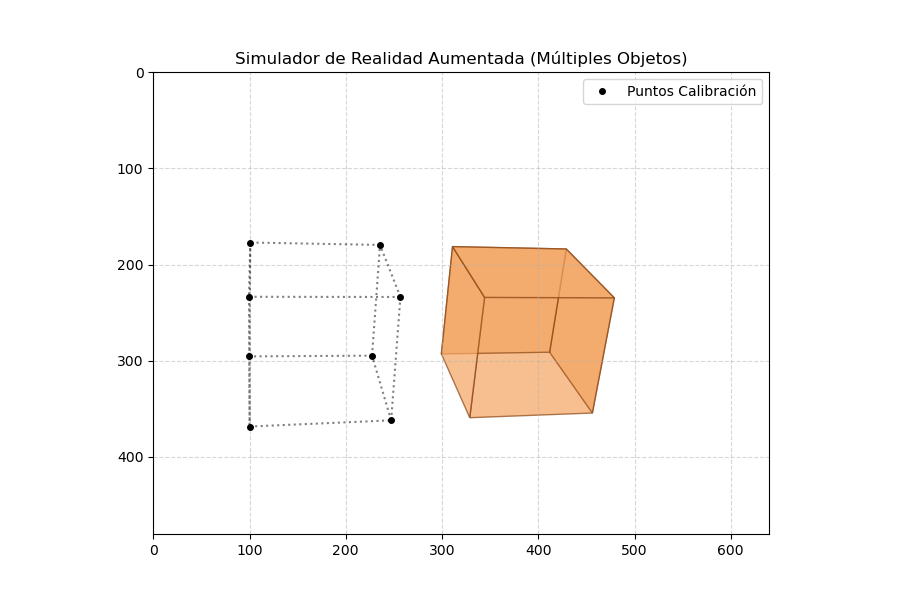

In [5]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from scipy.spatial.transform import Rotation as Rot

# ==========================================================================
# 1. FUNCIONES DLT Y NORMALIZACIÓN DE HARTLEY
# ==========================================================================
def normalizar_puntos_2d(pts):
    pts = np.array(pts, dtype=np.float64)
    centroid = np.mean(pts[:, :2], axis=0)
    pts_centrados = pts[:, :2] - centroid
    escala = np.sqrt(2.0) / np.mean(np.linalg.norm(pts_centrados, axis=1))
    return np.array([
        [escala, 0.0,    -escala * centroid[0]],
        [0.0,    escala, -escala * centroid[1]],
        [0.0,    0.0,    1.0]
    ], dtype=np.float64)

def normalizar_puntos_3d(pts):
    pts = np.array(pts, dtype=np.float64)
    centroid = np.mean(pts[:, :3], axis=0)
    pts_centrados = pts[:, :3] - centroid
    escala = np.sqrt(3.0) / np.mean(np.linalg.norm(pts_centrados, axis=1))
    return np.array([
        [escala, 0.0,    0.0,    -escala * centroid[0]],
        [0.0,    escala, 0.0,    -escala * centroid[1]],
        [0.0,    0.0,    escala, -escala * centroid[2]],
        [0.0,    0.0,    0.0,    1.0]
    ], dtype=np.float64)

def calibrar_camara_dlt(pts_3d, pts_2d):
    N = len(pts_3d)
    T2D = normalizar_puntos_2d(pts_2d)
    T3D = normalizar_puntos_3d(pts_3d)
    
    pts_2d_hom = np.hstack([pts_2d[:, :2], np.ones((N, 1))])
    pts_3d_hom = np.hstack([pts_3d[:, :3], np.ones((N, 1))])
    
    pts_2d_norm = (T2D @ pts_2d_hom.T).T
    pts_3d_norm = (T3D @ pts_3d_hom.T).T
    
    A = []
    for i in range(N):
        X = pts_3d_norm[i]
        u, v = pts_2d_norm[i, 0], pts_2d_norm[i, 1]
        A.append(np.hstack([np.zeros(4), -X,  v * X]))
        A.append(np.hstack([X,  np.zeros(4), -u * X]))
        
    _, _, Vt = np.linalg.svd(np.array(A, dtype=np.float64))
    M_norm = Vt[-1, :].reshape((3, 4))
    return np.linalg.inv(T2D) @ M_norm @ T3D

# ==========================================================================
# 2. DEFINICIÓN DEL MUNDO 3D Y CÁMARA
# ==========================================================================
# Matriz real secreta
f_real = 800.0
K_real = np.array([[f_real, 0, 320], [0, f_real, 240], [0, 0, 1]])

# Rotación y traslación para ver ambos objetos (Cubo a la izq, Casa a la der)
R_real = Rot.from_euler('xyz', [25, -15, 0], degrees=True).as_matrix()
t_real = np.array([[-30], [20], [600]]) 
M_real = K_real @ np.hstack([R_real, t_real])

# 1. Objeto Físico (Cubo de calibración desplazado a X = -80)
cubo_3d = np.array([
    [-130, 50, -50], [-30, 50, -50], [-30, 50, 50], [-130, 50, 50],  # Base inferior
    [-130, -50, -50], [-30, -50, -50], [-30, -50, 50], [-130, -50, 50] # Tope superior
], dtype=np.float64)

# Tomar foto del cubo y añadir ruido
cubo_2d = np.array([(M_real @ np.append(pt, 1.0))[:2] / (M_real @ np.append(pt, 1.0))[2] for pt in cubo_3d])
cubo_2d += np.random.normal(0, 0.5, (8, 2))

# ==========================================================================
# 3. ESTIMACIÓN DE M Y GEOMETRÍA VIRTUAL (AR)
# ==========================================================================
M_est = calibrar_camara_dlt(cubo_3d, cubo_2d)

# 2. Muros Virtuales (Desplazados a X = +80, misma escala)
muros_3d = np.array([
    [30, 50, -50], [130, 50, -50], [130, 50, 50], [30, 50, 50],    # Base inferior
    [30, -50, -50], [130, -50, -50], [130, -50, 50], [30, -50, 50] # Tope superior
], dtype=np.float64)

# 3. Tejado Virtual (Sobre los muros)
tejado_3d = np.array([
    [30, -50, -50], [130, -50, -50], [130, -50, 50], [30, -50, 50], # Base tejado
    [80, -120, 0]                                                   # Cúspide
], dtype=np.float64)

# Proyectar AR usando M_est
muros_2d = np.array([(M_est @ np.append(pt, 1.0))[:2] / (M_est @ np.append(pt, 1.0))[2] for pt in muros_3d])
tejado_2d = np.array([(M_est @ np.append(pt, 1.0))[:2] / (M_est @ np.append(pt, 1.0))[2] for pt in tejado_3d])

# ==========================================================================
# 4. INTERFAZ GRÁFICA Y RENDERIZADO (Matplotlib + Ipywidgets)
# ==========================================================================
fig, ax = plt.subplots(figsize=(9, 6))
ax.set_title("Simulador de Realidad Aumentada (Múltiples Objetos)")

# --- A. Render del Cubo Físico de Calibración ---
aristas_cubo = [(0,1), (1,2), (2,3), (3,0), (4,5), (5,6), (6,7), (7,4), (0,4), (1,5), (2,6), (3,7)]
for p1, p2 in aristas_cubo:
    ax.plot([cubo_2d[p1, 0], cubo_2d[p2, 0]], [cubo_2d[p1, 1], cubo_2d[p2, 1]], 
             color='black', linestyle=':', linewidth=1.5, alpha=0.5)
ax.plot(cubo_2d[:, 0], cubo_2d[:, 1], 'ko', markersize=4, label='Puntos Calibración')

# --- B. Render de Muros AR ---
caras_muros = [
    [muros_2d[0], muros_2d[1], muros_2d[5], muros_2d[4]], # Frontal
    [muros_2d[1], muros_2d[2], muros_2d[6], muros_2d[5]], # Derecha
    [muros_2d[2], muros_2d[3], muros_2d[7], muros_2d[6]], # Trasera
    [muros_2d[3], muros_2d[0], muros_2d[4], muros_2d[7]], # Izquierda
    [muros_2d[4], muros_2d[5], muros_2d[6], muros_2d[7]]  # Techo plano
]
for cara in caras_muros:
    poly = plt.Polygon(cara, closed=True, facecolor='sandybrown', edgecolor='saddlebrown', alpha=0.7)
    ax.add_patch(poly)

# --- C. Render del Tejado AR (Se guarda en una lista para alternar su visibilidad) ---
caras_tejado = [
    [tejado_2d[0], tejado_2d[1], tejado_2d[4]],
    [tejado_2d[1], tejado_2d[2], tejado_2d[4]],
    [tejado_2d[2], tejado_2d[3], tejado_2d[4]],
    [tejado_2d[3], tejado_2d[0], tejado_2d[4]]
]

elementos_tejado = []
for cara in caras_tejado:
    poly = plt.Polygon(cara, closed=True, facecolor='crimson', edgecolor='darkred', alpha=0.8)
    poly.set_visible(False) # Inicia oculto
    ax.add_patch(poly)
    elementos_tejado.append(poly)

# Configuración final de la vista
ax.set_xlim(0, 640)
ax.set_ylim(480, 0)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_aspect('equal')

# --- D. Lógica del Botón Interactivo ---
btn_tejado = widgets.Button(description="Añadir Tejado", button_style='info')
tejado_activo = False

def alternar_tejado(b):
    global tejado_activo
    tejado_activo = not tejado_activo
    
    # Mostrar u ocultar los polígonos del tejado
    for elemento in elementos_tejado:
        elemento.set_visible(tejado_activo)
        
    # Cambiar el texto del botón
    b.description = "Quitar Tejado" if tejado_activo else "Añadir Tejado"
    b.button_style = 'danger' if tejado_activo else 'info'
    
    # Refrescar el lienzo
    fig.canvas.draw_idle()

btn_tejado.on_click(alternar_tejado)

# Desplegar la interfaz
display(btn_tejado)
plt.show()